## Load the wallet data

In [ ]:
import pandas as pd

df = pd.read_csv("wallet_features.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (55952, 11)


,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed
0,w_b6640fc6a7,6,1,241.805798,0.576023,1.000000,88.3200,0.000322,1.598889,0.365252,False
1,w_ce85723407,6,4,33.230088,0.936964,0.405506,12.4750,0.000362,49.930856,1.501651,False
2,w_b92e826e83,7,4,43.640110,0.340639,0.483274,12.0000,0.000021,17.895579,1.099906,False
3,w_ab04538147,10,6,135.093199,0.204462,0.388621,52.5000,0.000559,19.121771,2.331724,False
4,w_09a7eb8ca6,13,13,64.902260,0.678542,0.077591,5.0358,0.000114,4.868113,1.008677,False


## Inspect column types and missing values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55952 entries, 0 to 55951
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   wallet                  55952 non-null  object 
 1   trade_count             55952 non-null  int64  
 2   unique_markets          55952 non-null  int64  
 3   total_notional          55952 non-null  float64
 4   avg_buy_price           55952 non-null  float64
 5   concentration           55952 non-null  float64
 6   max_single_buy          55952 non-null  float64
 7   market_notional_ratio   55952 non-null  float64
 8   wallet_age_days         55952 non-null  float64
 9   position_anomaly_ratio  55952 non-null  float64
 10  confirmed               55952 non-null  bool   
dtypes: bool(1), float64(7), int64(2), object(1)
memory usage: 4.3+ MB


## Summarize known-positive and unlabeled wallets

In [ ]:
label_counts = df["confirmed"].value_counts()
label_percentages = df["confirmed"].value_counts(normalize=True) * 100

print("Wallet counts:")
print(label_counts)

print("\nPercentage (%):")
print(label_percentages.round(4))

Wallet counts:
confirmed
False    55933
True        19
Name: count, dtype: int64

Percentage (%):
confirmed
False    99.966
True      0.034
Name: proportion, dtype: float64


## Calculate descriptive statistics

In [ ]:
summary_stats = df.describe().T
summary_stats

,count,mean,std,min,25%,50%,75%,max
trade_count,55952.0,74.888243,765.536114,3.000000,5.000000,10.000000,24.000000,5.988500e+04
unique_markets,55952.0,9.041464,23.006774,1.000000,3.000000,4.000000,8.000000,1.177000e+03
total_notional,55952.0,10481.786812,163481.228852,0.011400,46.421594,197.841175,982.089187,1.971762e+07
avg_buy_price,55952.0,0.669188,0.272842,0.001000,0.519950,0.732745,0.902192,9.990000e-01
concentration,55952.0,0.560874,0.255401,0.008329,0.357143,0.526763,0.759686,1.000000e+00
max_single_buy,55952.0,965.975317,8832.583882,0.004950,18.600000,63.951150,305.290822,1.016632e+06
market_notional_ratio,55952.0,0.004405,0.029763,0.000000,0.000018,0.000117,0.000669,1.000000e+00
wallet_age_days,55952.0,47.750300,69.911205,0.000000,4.789007,20.841204,50.745530,3.626167e+02
position_anomaly_ratio,55952.0,2.048703,2.325015,0.002622,1.035031,1.557361,2.364895,1.711854e+02


## Plot the distribution of trading amounts

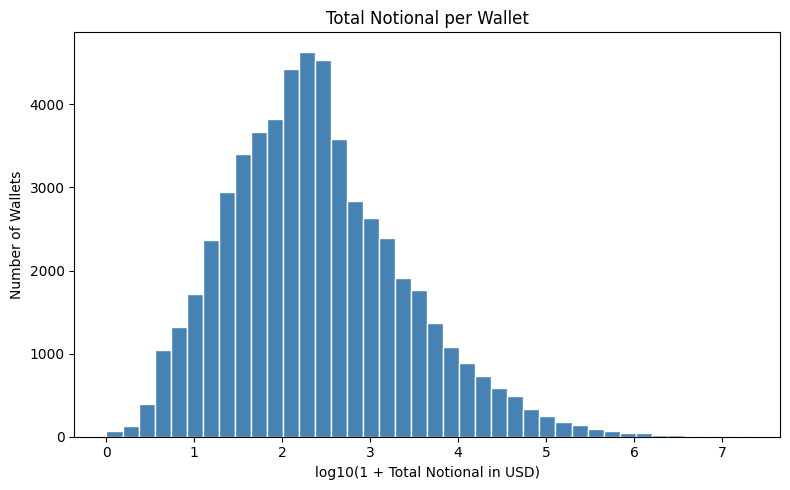

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

log_notional = np.log10(1 + df["total_notional"])

plt.figure(figsize=(8, 5))
plt.hist(log_notional, bins=40, color="steelblue", edgecolor="white")

plt.title("Total Notional per Wallet")
plt.xlabel("log10(1 + Total Notional in USD)")
plt.ylabel("Number of Wallets")

plt.tight_layout()
plt.savefig("total_notional_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Plot market participation

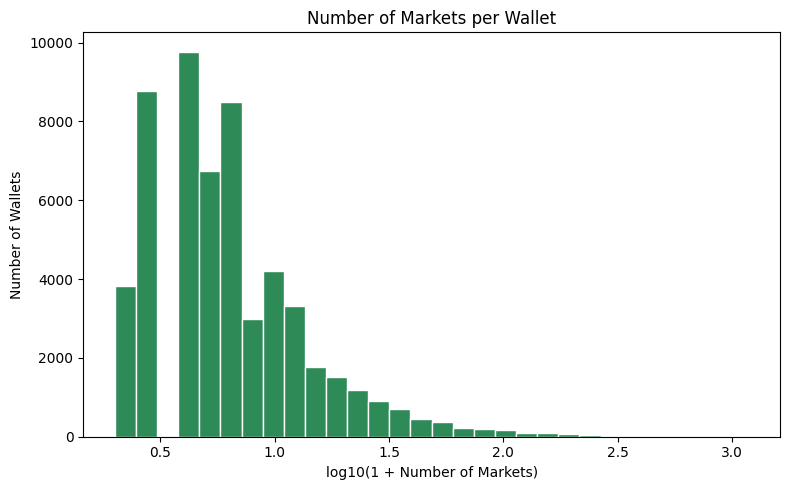

In [ ]:
log_markets = np.log10(1 + df["unique_markets"])

plt.figure(figsize=(8, 5))
plt.hist(log_markets, bins=30, color="seagreen", edgecolor="white")

plt.title("Number of Markets per Wallet")
plt.xlabel("log10(1 + Number of Markets)")
plt.ylabel("Number of Wallets")

plt.tight_layout()
plt.savefig("market_count_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Plot spending concentration.

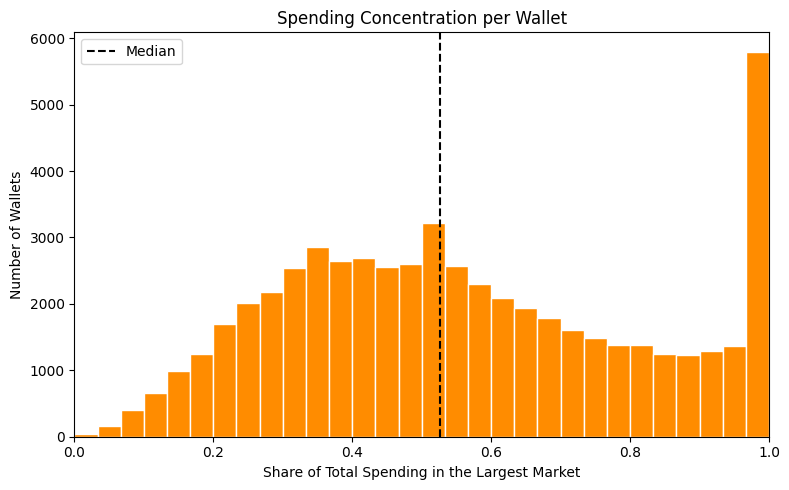

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["concentration"],
    bins=30,
    range=(0, 1),
    color="darkorange",
    edgecolor="white"
)

plt.axvline(
    df["concentration"].median(),
    color="black",
    linestyle="--",
    label="Median"
)

plt.title("Spending Concentration per Wallet")
plt.xlabel("Share of Total Spending in the Largest Market")
plt.ylabel("Number of Wallets")
plt.xlim(0, 1)
plt.legend()

plt.tight_layout()
plt.savefig("concentration_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Count wallets whose spending is concentrated in one market

In [ ]:
fully_concentrated = df["concentration"] == 1

print("Wallets with concentration = 1:", fully_concentrated.sum())
print("Percentage (%):", round(fully_concentrated.mean() * 100, 2))

Wallets with concentration = 1: 3834
Percentage (%): 6.85


## Plot the observed trading span

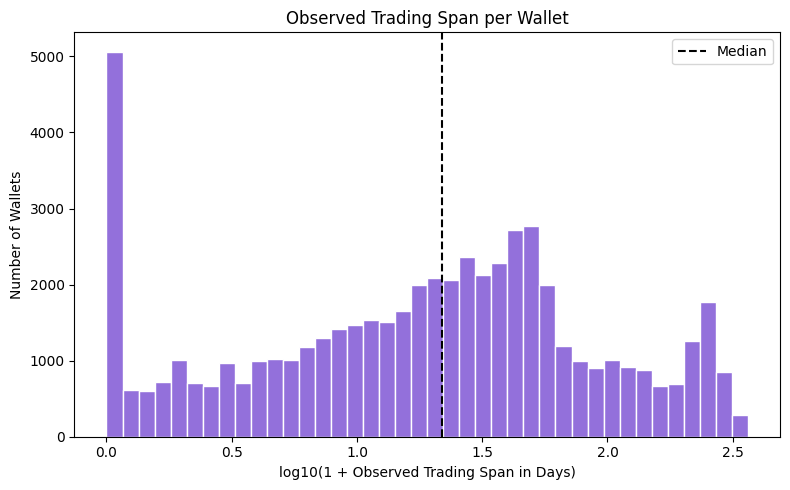

In [ ]:
log_span = np.log10(1 + df["wallet_age_days"])
median_span = df["wallet_age_days"].median()

plt.figure(figsize=(8, 5))
plt.hist(log_span, bins=40, color="mediumpurple", edgecolor="white")

plt.axvline(
    np.log10(1 + median_span),
    color="black",
    linestyle="--",
    label="Median"
)

plt.title("Observed Trading Span per Wallet")
plt.xlabel("log10(1 + Observed Trading Span in Days)")
plt.ylabel("Number of Wallets")
plt.legend()

plt.tight_layout()
plt.savefig("observed_trading_span_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## Select the nine numeric features for PCA

In [ ]:
features = [
    "total_notional",
    "max_single_buy",
    "trade_count",
    "market_notional_ratio",
    "avg_buy_price",
    "concentration",
    "position_anomaly_ratio",
    "wallet_age_days",
    "unique_markets"
]

X = df[features].copy()

print("PCA input shape:", X.shape)
X.head()

PCA input shape: (55952, 9)


,total_notional,max_single_buy,trade_count,market_notional_ratio,avg_buy_price,concentration,position_anomaly_ratio,wallet_age_days,unique_markets
0,241.805798,88.3200,6,0.000322,0.576023,1.000000,0.365252,1.598889,1
1,33.230088,12.4750,6,0.000362,0.936964,0.405506,1.501651,49.930856,4
2,43.640110,12.0000,7,0.000021,0.340639,0.483274,1.099906,17.895579,4
3,135.093199,52.5000,10,0.000559,0.204462,0.388621,2.331724,19.121771,6
4,64.902260,5.0358,13,0.000114,0.678542,0.077591,1.008677,4.868113,13


## Apply log1p to seven features

In [ ]:
log_features = [
    "total_notional",
    "max_single_buy",
    "trade_count",
    "market_notional_ratio",
    "position_anomaly_ratio",
    "wallet_age_days",
    "unique_markets"
]

X_transformed = X.copy()

X_transformed[log_features] = np.log1p(
    X_transformed[log_features]
)

print("Number of log-transformed features:", len(log_features))
X_transformed.head()

Number of log-transformed features: 7


,total_notional,max_single_buy,trade_count,market_notional_ratio,avg_buy_price,concentration,position_anomaly_ratio,wallet_age_days,unique_markets
0,5.492262,4.492225,1.945910,0.000322,0.576023,1.000000,0.311339,0.955084,0.693147
1,3.533105,2.600836,1.945910,0.000362,0.936964,0.405506,0.916951,3.930469,1.609438
2,3.798633,2.564949,2.079442,0.000021,0.340639,0.483274,0.741893,2.938928,1.609438
3,4.913340,3.979682,2.397895,0.000559,0.204462,0.388621,1.203490,3.001802,1.945910
4,4.188173,1.797708,2.639057,0.000114,0.678542,0.077591,0.697476,1.769533,2.639057


## Standardize all nine features

In [ ]:
feature_means = X_transformed.mean()
feature_stds = X_transformed.std(ddof=1)

X_scaled = (
    X_transformed - feature_means
) / feature_stds

print("Column means:")
print(X_scaled.mean().round(6))

print("\nColumn standard deviations:")
print(X_scaled.std(ddof=1).round(6))

print("\nStandardized data shape:", X_scaled.shape)

Column means:
total_notional           -0.0
max_single_buy           -0.0
trade_count               0.0
market_notional_ratio    -0.0
avg_buy_price            -0.0
concentration            -0.0
position_anomaly_ratio   -0.0
wallet_age_days          -0.0
unique_markets            0.0
dtype: float64

Column standard deviations:
total_notional            1.0
max_single_buy            1.0
trade_count               1.0
market_notional_ratio     1.0
avg_buy_price             1.0
concentration             1.0
position_anomaly_ratio    1.0
wallet_age_days           1.0
unique_markets            1.0
dtype: float64

Standardized data shape: (55952, 9)


## Fit PCA and calculate explained variance

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=len(features),
    svd_solver="full"
)

pca_scores = pca.fit_transform(X_scaled)

component_names = [
    f"PC{i + 1}" for i in range(pca.n_components_)
]

variance_table = pd.DataFrame({
    "Component": component_names,
    "Explained Variance (%)": (
        pca.explained_variance_ratio_ * 100
    ),
    "Cumulative Variance (%)": (
        np.cumsum(pca.explained_variance_ratio_) * 100
    )
})

variance_table.round(2)

,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,45.20,45.20
1,PC2,16.99,62.19
2,PC3,11.58,73.77
3,PC4,8.69,82.46
4,PC5,8.28,90.74
5,PC6,5.68,96.42
6,PC7,2.99,99.41
7,PC8,0.56,99.97
8,PC9,0.03,100.00


## Plot individual and cumulative explained variance

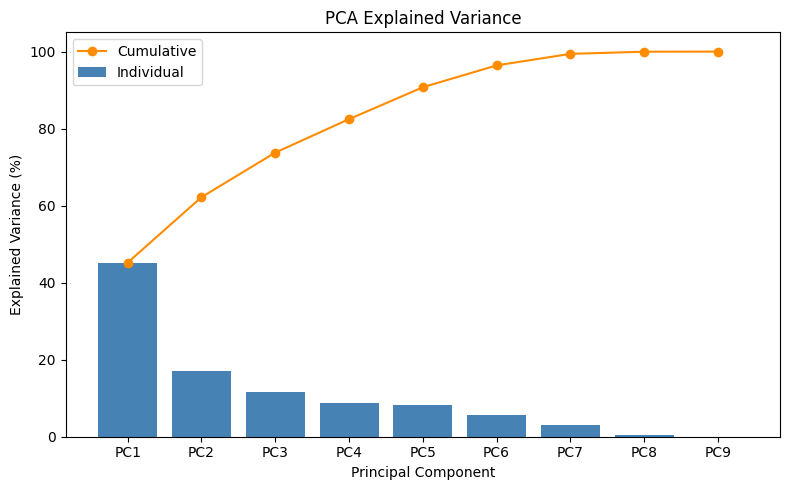

In [ ]:
components = variance_table["Component"]
individual_variance = variance_table["Explained Variance (%)"]
cumulative_variance = variance_table["Cumulative Variance (%)"]

plt.figure(figsize=(8, 5))

plt.bar(
    components,
    individual_variance,
    color="steelblue",
    label="Individual"
)

plt.plot(
    components,
    cumulative_variance,
    color="darkorange",
    marker="o",
    label="Cumulative"
)

plt.title("PCA Explained Variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.ylim(0, 105)
plt.legend()

plt.tight_layout()
plt.savefig("pca_explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()

## Project wallets onto the first two principal components

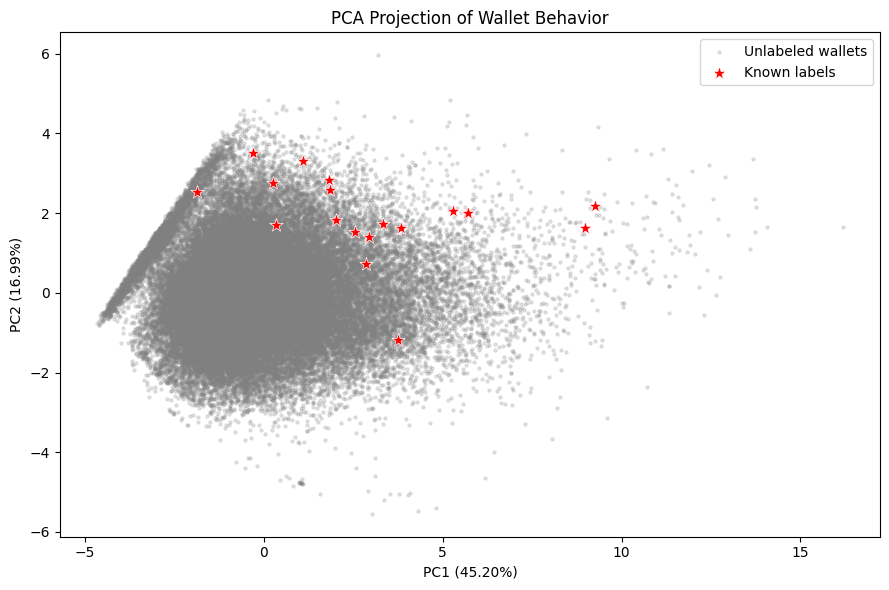

In [ ]:
pca_df = pd.DataFrame(
    pca_scores[:, :2],
    columns=["PC1", "PC2"],
    index=df.index
)

pca_df["confirmed"] = df["confirmed"]

unlabeled = pca_df[pca_df["confirmed"] == False]
labeled = pca_df[pca_df["confirmed"] == True]

plt.figure(figsize=(9, 6))

plt.scatter(
    unlabeled["PC1"],
    unlabeled["PC2"],
    s=5,
    alpha=0.2,
    color="gray",
    label="Unlabeled wallets"
)

plt.scatter(
    labeled["PC1"],
    labeled["PC2"],
    s=100,
    marker="*",
    color="red",
    edgecolors="white",
    linewidths=0.5,
    label="Known labels",
    zorder=3
)

plt.title("PCA Projection of Wallet Behavior")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}%)")
plt.legend()

plt.tight_layout()
plt.savefig("pca_wallet_projection.png", dpi=300, bbox_inches="tight")
plt.show()

## Inspect feature coefficients for PC1 and PC2

In [ ]:
component_coefficients = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=component_names
)

component_coefficients[["PC1", "PC2"]].round(3)

,PC1,PC2
total_notional,0.399,0.428
max_single_buy,0.336,0.551
trade_count,0.432,-0.020
market_notional_ratio,0.235,0.071
avg_buy_price,0.171,0.252
concentration,-0.281,0.503
position_anomaly_ratio,0.280,-0.153
wallet_age_days,0.327,-0.277
unique_markets,0.438,-0.302


## Plot the PCA component coefficients

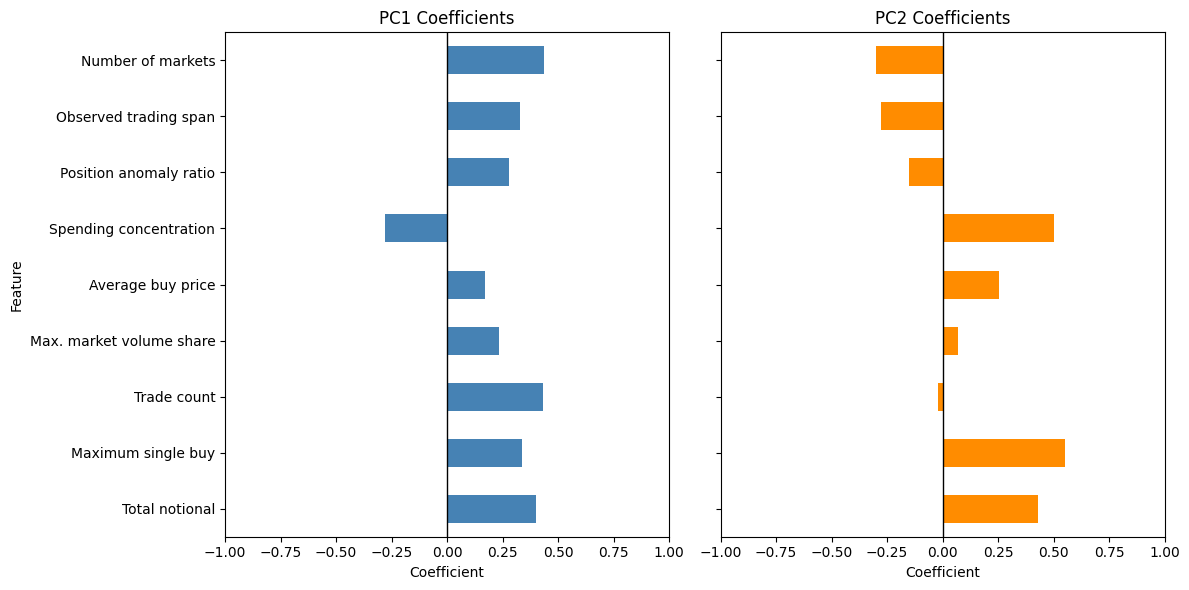

In [ ]:
plot_coefficients = component_coefficients[["PC1", "PC2"]].copy()

plot_coefficients.index = [
    "Total notional",
    "Maximum single buy",
    "Trade count",
    "Max. market volume share",
    "Average buy price",
    "Spending concentration",
    "Position anomaly ratio",
    "Observed trading span",
    "Number of markets"
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    sharey=True
)

for ax, component, color in zip(
    axes,
    ["PC1", "PC2"],
    ["steelblue", "darkorange"]
):
    plot_coefficients[component].plot.barh(
        ax=ax,
        color=color
    )

    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{component} Coefficients")
    ax.set_xlabel("Coefficient")
    ax.set_xlim(-1, 1)

axes[0].set_ylabel("Feature")

plt.tight_layout()
plt.savefig(
    "pca_component_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Export descriptive statistics and PCA results

In [ ]:
summary_stats.to_csv(
    "summary_statistics.csv",
    index_label="Feature"
)

variance_table.to_csv(
    "pca_explained_variance.csv",
    index=False
)

component_coefficients.to_csv(
    "pca_component_coefficients.csv",
    index_label="Feature"
)

pca_export = pca_df.copy()
pca_export.insert(0, "wallet", df["wallet"])

pca_export.to_csv(
    "pca_wallet_coordinates.csv",
    index=False
)

print("Saved 4 result tables.")

Saved 4 result tables.
